In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
from pylab import rcParams
import matplotlib.pyplot as plt
import warnings
from mlxtend.plotting import plot_decision_regions
from matplotlib.colors import ListedColormap
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_circles
import seaborn as sns


In [4]:
X,y=make_circles(n_samples=100, noise=0.1, random_state=1)

<Axes: >

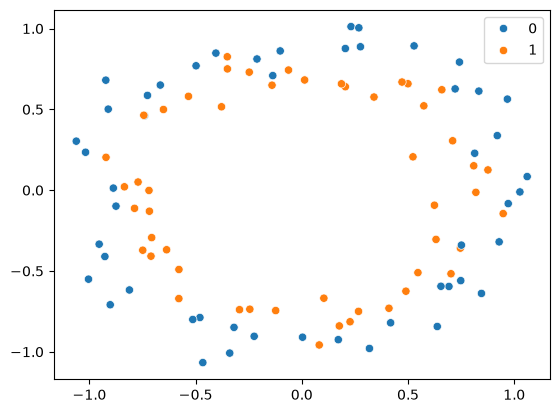

In [9]:
sns.scatterplot(x=X[:,0],y=X[:,1],hue=y)

In [50]:
X_train, X_test , y_train,y_test=train_test_split(X, y , test_size=0.2, random_state=2 )

In [51]:
model=Sequential()

model.add(Dense(256, input_dim=2 , activation='relu'))
model.add(Dense(1, activation='sigmoid'))

In [52]:
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])


In [53]:
history=model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=3500, verbose=0)

KeyboardInterrupt: 

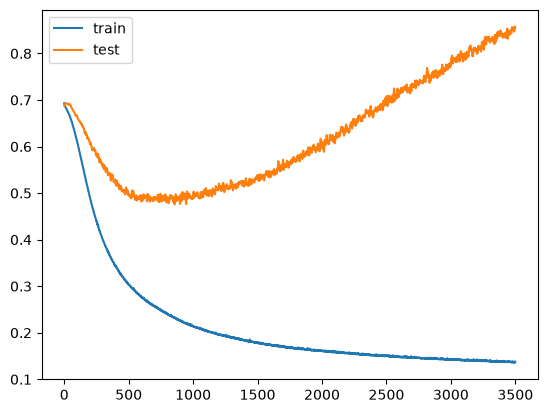

In [24]:
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='test')
plt.legend()
plt.show()

In [43]:
print(X_test.dtype)
print(X_test.shape)
print(y_test.dtype)

float64
(20, 2)
int64


9600/9600 ━━━━━━━━━━━━━━━━━━━━ 33s 3ms/step


TypeError: ufunc 'isfinite' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''

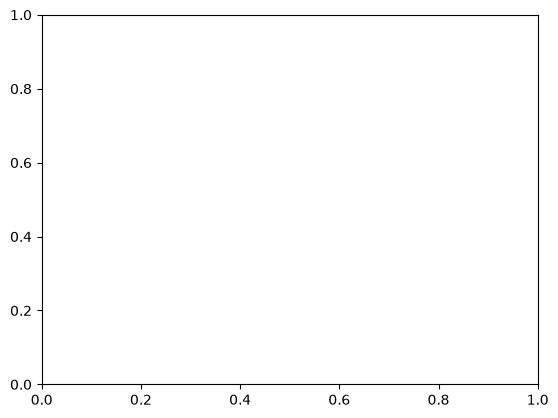

In [46]:
plot_decision_regions(X_test, y_test.ravel(), clf = model, legend=2)
plt.show()

## Early stopping


In [54]:
model=Sequential()

model.add(Dense(256, input_dim=2, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

In [55]:
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])


In [56]:
callback = EarlyStopping(
    monitor="val_loss",
    min_delta=0.00001,
    patience=20,
    verbose=1,
    mode="auto",
    baseline=None,
    restore_best_weights=False
)

In [57]:
history=model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=3500, callbacks=callback)

Epoch 1/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 232ms/step - accuracy: 0.5000 - loss: 0.6981 - val_accuracy: 0.4500 - val_loss: 0.6965
Epoch 2/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step - accuracy: 0.5125 - loss: 0.6963 - val_accuracy: 0.5500 - val_loss: 0.6976
Epoch 3/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.5000 - loss: 0.6936 - val_accuracy: 0.5000 - val_loss: 0.6984
Epoch 4/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.5125 - loss: 0.6923 - val_accuracy: 0.3500 - val_loss: 0.7003
Epoch 5/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.5250 - loss: 0.6910 - val_accuracy: 0.3500 - val_loss: 0.7017
Epoch 6/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - accuracy: 0.5500 - loss: 0.6896 - val_accuracy: 0.4000 - val_loss: 0.7031
Epoch 7/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.5625 - loss: 0.6890 - val_accuracy: 0.4000 - val_loss: 0.7052
Epoch 8/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.5625 - loss: 0.6878 - val_accuracy: 0.4000 -

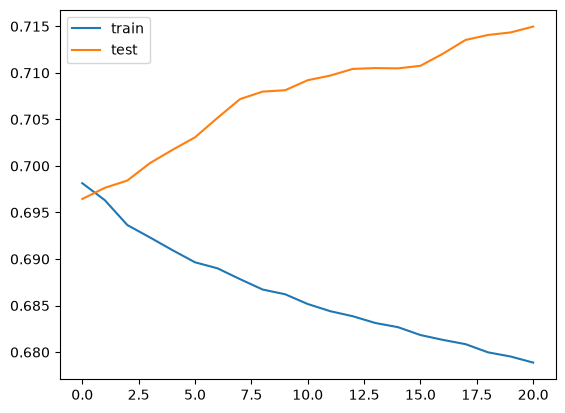

In [58]:
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='test')
plt.legend()
plt.show()

9600/9600 ━━━━━━━━━━━━━━━━━━━━ 31s 3ms/step


TypeError: ufunc 'isfinite' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''

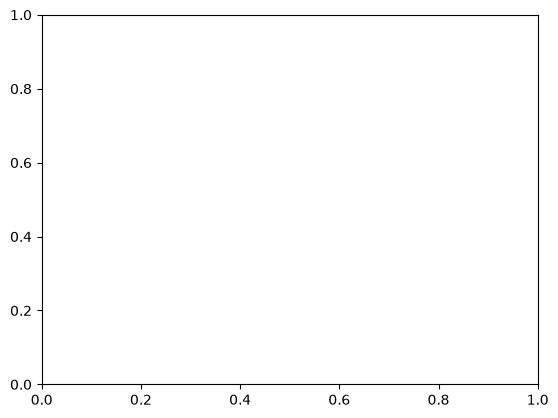

In [60]:
plot_decision_regions(X_test, y_test.ravel(), clf = model)
plt.show()